<a href="https://colab.research.google.com/github/Devikakrishnau/github-slideshow/blob/main/Drowsiness_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files
uploaded = files.upload()  # Select DrowsinessDataset_Split.zip


Saving DrowsinessDataset_Split.zip to DrowsinessDataset_Split.zip


In [4]:
import os, zipfile, shutil

zipname = "DrowsinessDataset_Split.zip"   # exact file name
extract_to = "/content/dataset"

# Clean old copy if exists
if os.path.exists(extract_to):
    shutil.rmtree(extract_to)

with zipfile.ZipFile(zipname, 'r') as zf:
    zf.extractall(extract_to)

print("Unzipped to:", extract_to)
print(os.listdir(extract_to))  # should show: DrowsinessDataset_Split


Unzipped to: /content/dataset
['DrowsinessDataset_Split 2.zip', '__MACOSX']


In [8]:
train_dir = "/content/dataset/DrowsinessDataset_Split 2.zip/train"
val_dir   = "/content/dataset/DrowsinessDataset_Split 2.zip/val"
test_dir  = "/content/dataset/DrowsinessDataset_Split 2.zip/test"

print("Train dir:", train_dir)
print("Val dir:", val_dir)
print("Test dir:", test_dir)

Train dir: /content/dataset/DrowsinessDataset_Split 2.zip/train
Val dir: /content/dataset/DrowsinessDataset_Split 2.zip/val
Test dir: /content/dataset/DrowsinessDataset_Split 2.zip/test


In [6]:
# ============================
# 📌 Cell 4: Import libraries & set image size
# ============================

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


In [10]:
# ============================
# 📌 Cell 5: Data Generators
# ============================

IMG_SIZE = (128, 128)  # you can try (224,224) for stronger models
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_gen = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_gen = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 1843 images belonging to 2 classes.
Found 965 images belonging to 2 classes.
Found 1193 images belonging to 2 classes.


In [9]:
# ============================
# 📌 Cell 6: Build CNN model
# ============================
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')  # Sigmoid for binary classification
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',  # Binary crossentropy for binary classification
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# ============================
# 📌 Cell 7: Train the model
# ============================
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)


Epoch 1/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.9892 - loss: 0.0387 - val_accuracy: 0.8083 - val_loss: 1.0368
Epoch 2/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step - accuracy: 0.9990 - loss: 0.0026 - val_accuracy: 0.8487 - val_loss: 0.8161
Epoch 3/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.9994 - loss: 0.0025 - val_accuracy: 0.8073 - val_loss: 1.1452
Epoch 4/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.9983 - loss: 0.0071 - val_accuracy: 0.8114 - val_loss: 1.2869
Epoch 5/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 1.0000 - loss: 5.0435e-04 - val_accuracy: 0.8280 - val_loss: 1.1584
Epoch 6/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.9983 - loss: 0.0054 - val_accuracy: 0.8736 - val_loss: 0.6382
Epoch 7/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 91s 2s/step - accuracy: 0.9986 - loss: 0.0036 - val_accuracy: 0.7741 - val_loss: 1.9534
Epoch 8/10
58/58 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9977 - loss: 0.0054 - val_accuracy: 0.8155 - val_

In [15]:
# ============================
# 📌 Cell 8: Evaluate on test set
# ============================
test_loss, test_acc = model.evaluate(test_gen)
print("Test Accuracy:", test_acc)


38/38 ━━━━━━━━━━━━━━━━━━━━ 13s 334ms/step - accuracy: 0.9441 - loss: 0.2916
Test Accuracy: 0.9656328558921814


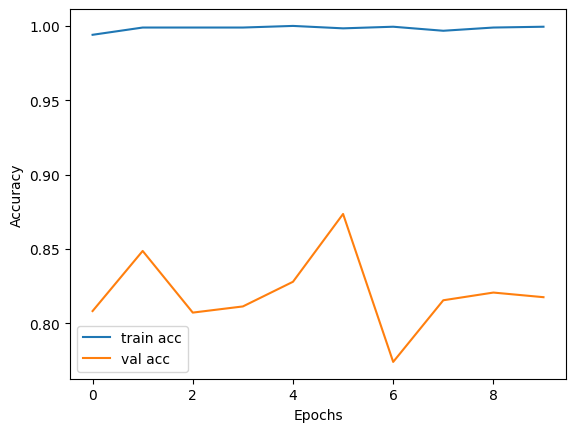

In [16]:
# ============================
# 📌 Cell 9: Plot training curves
# ============================
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [19]:
# ============================
# 📌 Cell 10: Predict on a single uploaded image
# ============================
from tensorflow.keras.preprocessing import image
import numpy as np
from google.colab import files

# Upload an image to test
print("Please upload an image file (e.g., .jpg, .png) to test the model.")
uploaded = files.upload()

for fname in uploaded.keys():
    img_path = fname
    try:
        img = image.load_img(img_path, target_size=IMG_SIZE)
        img_array = image.img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        prediction = model.predict(img_array)[0][0]

        if prediction > 0.5:
            print(f"{fname} --> Prediction : Opened Eyes 👀")
        else:
            print(f"{fname} --> Prediction : Closed Eyes 😴")
    except Exception as e:
        print(f"Error processing {fname}: {e}")

Please upload an image file (e.g., .jpg, .png) to test the model.


Saving s0034_00168_0_0_1_0_0_02.png to s0034_00168_0_0_1_0_0_02.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
s0034_00168_0_0_1_0_0_02.png --> Prediction : Opened Eyes 👀


In [20]:
# ============================
# 📌 Cell 10 (Alternative): Predict on the entire test folder
# ============================
import numpy as np

# Get predictions for all test images
pred_probs = model.predict(test_gen)
pred_labels = (pred_probs > 0.5).astype(int).ravel()  # 0 = Closed, 1 = Open

# True labels from generator
true_labels = test_gen.classes
class_names = list(test_gen.class_indices.keys())  # ['Closed', 'Opened'] (order depends on folder)

# Print first 20 predictions as sample
for i in range(20):
    fname = test_gen.filenames[i]
    true_class = class_names[true_labels[i]]
    pred_class = class_names[pred_labels[i]]
    print(f"{fname} --> True: {true_class}, Predicted : {pred_class}")


38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 325ms/step
Closed_Eyes/s0016_00205_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00206_1_0_0_1_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00207_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00208_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00209_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00210_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00211_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00212_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00213_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00214_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
Closed_Eyes/s0016_00215_1_0_0_0_1_01.png --> True: Closed_Eyes, Predicted: Closed_Eyes
C

In [35]:
# ============================
# 📌 Cell 10a: Upload test_images.zip
# ============================
from google.colab import files
import zipfile, os, shutil

uploaded = files.upload()  # Select your test zip (e.g., test_images.zip)

zipname = list(uploaded.keys())[0]
extract_to = "/content/test_images"

# Remove old folder if exists
if os.path.exists(extract_to):
    shutil.rmtree(extract_to)

with zipfile.ZipFile(zipname, 'r') as zf:
    zf.extractall(extract_to)

print("Extracted to:", extract_to)
print("Number of files:", len(os.listdir(extract_to)))


Saving test.zip to test (2).zip
Extracted to: /content/test_images
Number of files: 2


In [39]:
# ============================
# 📌 Cell 10b (fixed): Predict on ALL extracted images
# ============================
from tensorflow.keras.preprocessing import image
import numpy as np
import os

results = []

# Walk through all subfolders
for root, dirs, files in os.walk(extract_to):
    for fname in files:
        if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(root, fname)

            try:
                # Preprocess
                img = image.load_img(img_path, target_size=IMG_SIZE)
                img_array = image.img_to_array(img) / 255.0
                img_array = np.expand_dims(img_array, axis=0)

                # Predict
                prediction = model.predict(img_array, verbose=0)[0][0] # Set verbose=0 to hide progress bars

                if prediction > 0.5:
                    label = "Opened Eyes 👀"
                else:
                    label = "Closed Eyes 😴"

                results.append((fname, label, float(prediction)))
            except Exception as e:
                print(f"Skipping file {fname} due to error: {e}")


# Check results
print("Total images processed:", len(results))
for r in results[:20]:  # Show first 20 results
    print(f"{r[0]} --> {r[1]} (confidence: {r[2]:.4f})")

Skipping file ._s0034_00403_0_0_1_0_0_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0034_00607_0_0_1_0_0_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0014_07538_0_0_1_2_1_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0034_00612_0_0_1_0_0_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0034_00512_0_0_1_0_0_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0014_07544_0_0_1_2_1_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0014_07515_0_0_1_2_1_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>
Skipping file ._s0034_00509_0_0_1_0_0_02.png due to error: cannot identify image file <_io.BytesIO object at 0x7a0fbd9a1cb0>


In [41]:
import pandas as pd

df = pd.DataFrame(results, columns=["Filename", "Prediction", "Confidence"])
df.to_csv("test_predictions.csv", index=False)

from google.colab import files
files.download("test_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>